In [100]:
import pandas as pd

client_train_data = pd.read_csv("data/client_train.csv", low_memory=False)
invoice_train_data = pd.read_csv("data/invoice_train.csv",  low_memory=False)

In [101]:
train_data = client_train_data.merge(invoice_train_data, on="client_id", how = "left", validate="1:m")

<Axes: xlabel='target', ylabel='count'>

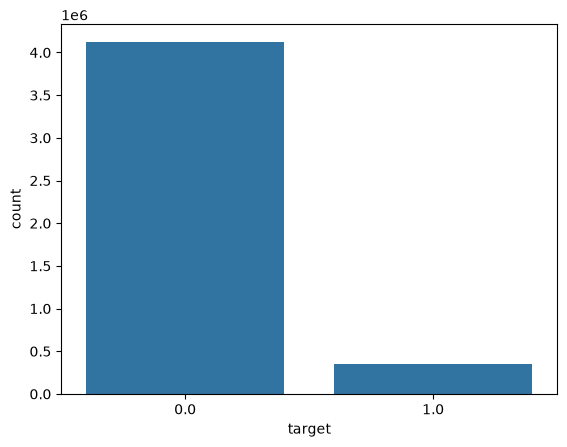

In [102]:
import seaborn as sns
sns.countplot(data=train_data, x="target")
# We see a very imbalanced result

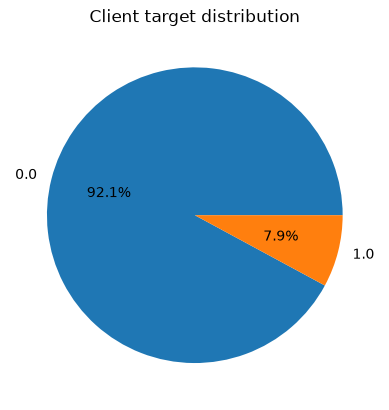

In [103]:
import matplotlib.pyplot as plt

target_counts = train_data["target"].value_counts().sort_index()
plt.pie(
    target_counts,
    labels=target_counts.index,
    autopct="%1.1f%%"
)
plt.title("Client target distribution")
plt.show()

In [104]:
X = train_data[
    ["client_catg", "region", "tarif_type", "counter_type", "reading_remarque",
      "months_number", "counter_coefficient", "counter_number", "consommation_level_1",
      "consommation_level_2", "counter_type", "old_index", "new_index", "creation_date"]
]
y = train_data["target"]

In [ ]:
d={"ELEC":0,"GAZ":1}
X = X.loc[:, ~X.columns.duplicated()].copy()
X["counter_type"] = X["counter_type"].map(d)
X['client_catg'] = X['client_catg'].astype(int)

X["creation_date"] = pd.to_datetime(X["creation_date"]).astype("int64")
#X['disrict'] = X['disrict'].astype(int)

In [107]:
# If the result is negative, this might indicate a fraud. This is *drumroll* FEATURE ENGINEERING!
X["diff_index"] = X["new_index"] - X["old_index"]

<Axes: >

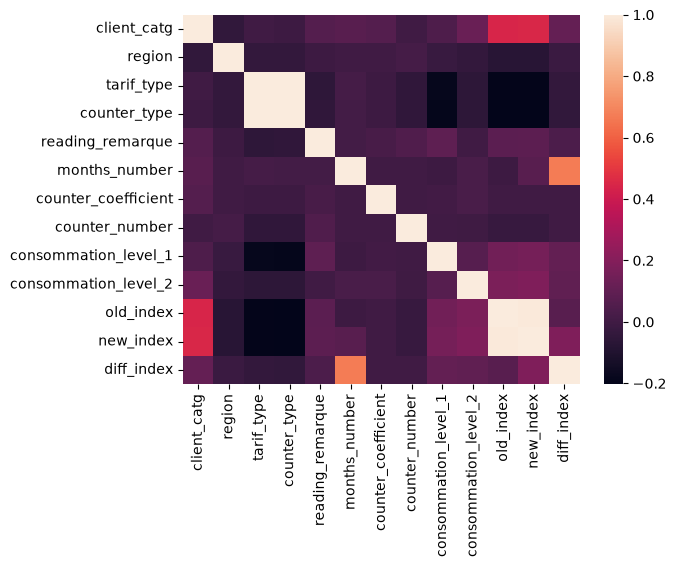

In [109]:
cm = X.select_dtypes(include=["number"]).corr(method="pearson")
sns.heatmap(cm)

In [110]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y, train_size=0.75)

In [111]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
# Convert the date column to a numeric timestamp before scaling
x_scaled = sc.fit_transform(X_train)

ValueError: could not convert string to float: '11/05/2009'

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

lgbm = LGBMClassifier()
pg = {
    "learning_rate": [0.01, 0.1, 0.2, 1],
    "n_estimators": [10, 100, 200],
    "subsample_for_bin": [1000, 10000, 20000],
}
gscv = GridSearchCV(
    estimator=lgbm,
    param_grid=pg,
    n_jobs=8,
    scoring="roc_auc"
)

gscv.fit(x_scaled, y_train)

In [ ]:
y_pred = gscv.predict(X_test)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
